# SurfaceGuard AI: Industrial Surface Anomaly Segmentation
Building a vision system that can find the problem, identify its category, and mark exactly where it occurs.

# 0. Overview
Modern manufacturing relies on automated visual inspection to catch quality issues before products leave the production line.

This notebooks focuses on building an AI inspection system that finds surface anomalies in industrial images, identifies their type, and marks exactly which pixels they cover. It is not enough to say whether an image contains a defect: your model must localize every anomaly at the pixel level, for four different anomaly categories.

Submissions are scored on how accurately the predicted masks match the true anomaly regions, and on how reliably the model avoids reporting anomalies that are not there.

# Evaluation Metric

Submissions are evaluated using a weighted segmentation metric designed specifically for this competition.

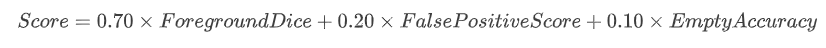

# 1. Setup

In [37]:
#installing necessary libraries
import os, glob, hashlib
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image 
from tqdm.auto import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import wandb


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# 2. Load Dataset

In [38]:
ROOT      = "/kaggle/input/competitions/industrial-surface-defect-detection/public"
TRAIN_DIR = f"{ROOT}/train"
TEST_DIR  = f"{ROOT}/test"

In [39]:
train   = pd.read_csv(f"{ROOT}/train.csv", keep_default_na=False)
sample_sub = pd.read_csv(f"{ROOT}/sample_submission.csv", keep_default_na=False)

# 3. Exploratory Data Analysis

In [40]:
#printing columns of train
train.columns

Index(['image_id', 'defect_type', 'mask_rle', 'width', 'height'], dtype='object')

In [41]:
train.dtypes

image_id       object
defect_type    object
mask_rle       object
width           int64
height          int64
dtype: object

In [42]:
#printing first 5 rows of train data
train.head(5)

,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,,800,128
2,4S22I7SA34,defect_c,,800,128
3,4S22I7SA34,defect_d,,800,128
4,DZ899111OE,defect_a,,800,128


In [43]:
#missing values
train.isna().sum()

image_id       0
defect_type    0
mask_rle       0
width          0
height         0
dtype: int64

In [44]:
#no.of rows in train data
print("Rows: ",len(train))

#no. of unique images in train data
print("Unique images: ", train['image_id'].nunique())

Rows:  45572
Unique images:  11393


In [45]:
# rows per image
print(train.groupby('image_id').size().value_counts())

4    11393
Name: count, dtype: int64


In [46]:
# picking the first image id
sample_id = train['image_id'].iloc[0]

# show all rows for this image id
train[train['image_id'] == sample_id]

,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,,800,128
2,4S22I7SA34,defect_c,,800,128
3,4S22I7SA34,defect_d,,800,128


### Insights:
* All 11,393 images have exactly 4 rows, so the rows are one per defect type rather than duplicates.
* mask_rle has a value if image has that type of defect. For rest of the defect types mask_rle has NaN.



In [47]:
#understanding the unique types of defect in images
train['defect_type'].unique()

array(['defect_a', 'defect_b', 'defect_c', 'defect_d'], dtype=object)

### Insights:
The are 4 types of defects found in the data:
* defect_a
* defect_b
* defect_c
* defect_d


In [48]:
#understanding the width of images in data
train['width'].unique()

array([800])

In [49]:
#understanding the height of images in data
train['height'].unique()

array([128])

### Insights:
All the images are of same size. ie. width=800 and height=128

In [50]:
#creating a column has_mask with True value wherever mask_rle is not NaN.
train['has_mask']=train['mask_rle'].fillna("").astype(str).str.strip().ne("")

In [51]:
##finding positive count per defect
train.groupby("defect_type").has_mask.sum().astype(int)

defect_type
defect_a    1081
defect_b     313
defect_c    4100
defect_d    1707
Name: has_mask, dtype: int64

In [52]:
CLASSES= ["defect_a", "defect_b", "defect_c", "defect_d"]
H,W= 128,800

COLORS= ["tab:red", "tab:green", "tab:blue", "tab:orange"]

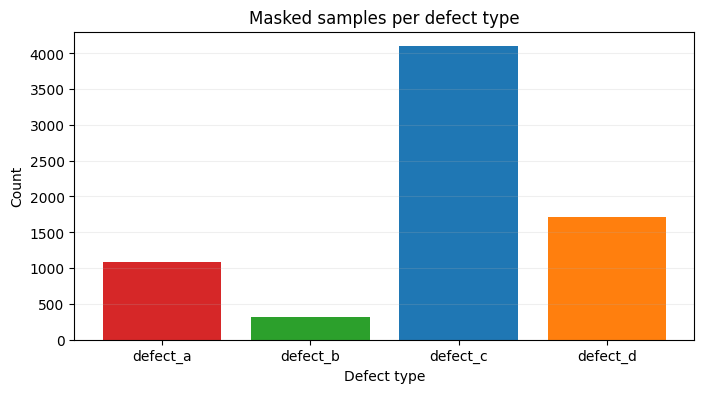

In [53]:
# count of masked samples for each defect type
counts = train.groupby("defect_type").has_mask.sum().astype(int)

plt.figure(figsize=(8, 4))
plt.bar(counts.index, counts.values, color=COLORS)
plt.title("Masked samples per defect type")
plt.xlabel("Defect type")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.2)
plt.show()

In [54]:
##getting defects per image
defects_per_img=train.groupby('image_id').has_mask.sum()

## images with no. of defects
no_defect_imgs=(defects_per_img == 0).sum()
one_defect_imgs=(defects_per_img == 1).sum()
two_defect_imgs=(defects_per_img == 2).sum()
three_defect_imgs=(defects_per_img == 3).sum()
four_defect_imgs=(defects_per_img == 4).sum()

print(f"No. of images with 0 defects: {no_defect_imgs}")
print(f"No. of images with 1 defect: {one_defect_imgs}")
print(f"No. of images with 2 defects: {two_defect_imgs}")
print(f"No. of images with 3 defects: {three_defect_imgs}")
print(f"No. of images with 4 defects: {four_defect_imgs}")

No. of images with 0 defects: 5516
No. of images with 1 defect: 4679
No. of images with 2 defects: 1072
No. of images with 3 defects: 126
No. of images with 4 defects: 0


In [55]:
  print(no_defect_imgs + one_defect_imgs + two_defect_imgs + three_defect_imgs + four_defect_imgs)
  print(train.image_id.nunique())

11393
11393


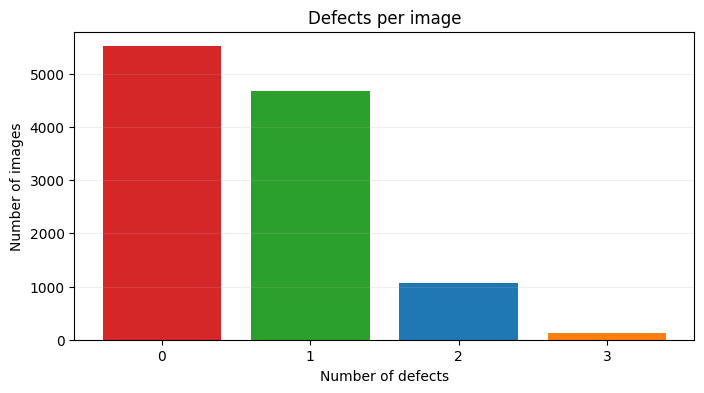

In [56]:
# number of defects in each image
defects_per_img = train.groupby("image_id").has_mask.sum().astype(int)

# how many images have 0, 1, 2, 3, 4 defects
dist = defects_per_img.value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(dist.index, dist.values, color=COLORS)
plt.title("Defects per image")
plt.xlabel("Number of defects")
plt.ylabel("Number of images")
plt.xticks(dist.index)
plt.grid(axis="y", alpha=0.2)
plt.show()

In [57]:
# Co occurance Cardinality
(train.groupby('image_id').has_mask.sum() > 1).value_counts()

has_mask
False    10195
True      1198
Name: count, dtype: int64

# 4. Data Preprocessing

In [58]:
def rle_decode(rle, shape=(H, W)):
    if str(rle).strip() in ("", "nan"):
        return np.zeros(shape, dtype=np.uint8)
    numbers = np.array(str(rle).split(), dtype=int)
    starts = numbers[0::2] - 1
    lengths = numbers[1::2]
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    for start, length in zip(starts, lengths):
        flat[start:start + length] = 1
    return flat.reshape(shape, order="F")


def rle_encode(mask):
    pixels = mask.flatten(order="F")
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[0::2]
    return " ".join(str(number) for number in runs)


def build_mask(rows, shape=(H, W)):
    mask = np.zeros((shape[0], shape[1], len(CLASSES)), dtype=np.uint8)
    for channel, defect in enumerate(CLASSES):
        match = rows[rows["defect_type"] == defect]
        if len(match) > 0:
            mask[:, :, channel] = rle_decode(match.iloc[0]["mask_rle"], shape)
    return mask

In [59]:
mismatches = 0
for rle in train[train["has_mask"]]["mask_rle"].head(500):
    if rle_encode(rle_decode(rle)) != rle.strip():
        mismatches += 1
print("mismatches:", mismatches)

mismatches: 0


# 5. Train and Validation Split

In [60]:
image_ids = train["image_id"].unique()
random_generator = np.random.default_rng(42)
random_generator.shuffle(image_ids)

split_point = int(0.9 * len(image_ids))
train_ids = image_ids[:split_point]
val_ids = image_ids[split_point:]

print("train images:", len(train_ids), "| val images:", len(val_ids))

train images: 10253 | val images: 1140


In [61]:
mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

In [62]:
class DefectDataset(Dataset):
    def __init__(self, image_ids, dataframe, folder, augment=False):
        self.image_ids = image_ids
        self.groups = {name: group for name, group in dataframe.groupby("image_id")}
        self.folder = folder
        self.augment = augment

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        image = cv2.imread(f"{self.folder}/{image_id}.jpg")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = build_mask(self.groups[image_id])

        if self.augment and np.random.rand() < 0.5:
            image = np.fliplr(image).copy()
            mask = np.fliplr(mask).copy()

        image = image.astype(np.float32) / 255.0
        image = (image - mean) / std
        image = torch.from_numpy(image).permute(2, 0, 1).float()
        mask = torch.from_numpy(mask).permute(2, 0, 1).float()
        return image, mask

In [63]:
train_dataset = DefectDataset(train_ids, train, TRAIN_DIR, augment=True)
val_dataset = DefectDataset(val_ids, train, TRAIN_DIR, augment=False)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)

# 6. Metrics

In [64]:
def dice_score(predictions, targets, threshold=0.5, epsilon=1e-7):
    predictions = (predictions > threshold).float()
    intersection = (predictions * targets).sum(dim=(0, 2, 3))
    union = predictions.sum(dim=(0, 2, 3)) + targets.sum(dim=(0, 2, 3))
    return (2 * intersection + epsilon) / (union + epsilon)


def f1_score(predictions, targets, threshold=0.5, epsilon=1e-7):
    predictions = (predictions > threshold).float()
    true_positive = (predictions * targets).sum(dim=(0, 2, 3))
    false_positive = (predictions * (1 - targets)).sum(dim=(0, 2, 3))
    false_negative = ((1 - predictions) * targets).sum(dim=(0, 2, 3))
    precision = true_positive / (true_positive + false_positive + epsilon)
    recall = true_positive / (true_positive + false_negative + epsilon)
    return 2 * precision * recall / (precision + recall + epsilon)

# 7. Loss

In [65]:
bce_loss = nn.BCEWithLogitsLoss()


def dice_loss(logits, targets, epsilon=1e-7):
    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * targets).sum(dim=(0, 2, 3))
    union = probabilities.sum(dim=(0, 2, 3)) + targets.sum(dim=(0, 2, 3))
    dice = (2 * intersection + epsilon) / (union + epsilon)
    return 1 - dice.mean()


def combined_loss(logits, targets):
    return bce_loss(logits, targets) + dice_loss(logits, targets)

# 8. Pretrained Model

In [66]:
def double_convolution(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, 3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )


class UNetFromScratch(nn.Module):
    def __init__(self, in_channels=3, num_classes=4, base=32):
        super().__init__()
        self.encoder1 = double_convolution(in_channels, base)
        self.encoder2 = double_convolution(base, base * 2)
        self.encoder3 = double_convolution(base * 2, base * 4)
        self.encoder4 = double_convolution(base * 4, base * 8)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = double_convolution(base * 8, base * 16)

        self.upconv4 = nn.ConvTranspose2d(base * 16, base * 8, 2, stride=2)
        self.decoder4 = double_convolution(base * 16, base * 8)
        self.upconv3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.decoder3 = double_convolution(base * 8, base * 4)
        self.upconv2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.decoder2 = double_convolution(base * 4, base * 2)
        self.upconv1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.decoder1 = double_convolution(base * 2, base)

        self.output = nn.Conv2d(base, num_classes, 1)

    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.decoder4(torch.cat([self.upconv4(b), e4], dim=1))
        d3 = self.decoder3(torch.cat([self.upconv3(d4), e3], dim=1))
        d2 = self.decoder2(torch.cat([self.upconv2(d3), e2], dim=1))
        d1 = self.decoder1(torch.cat([self.upconv1(d2), e1], dim=1))

        return self.output(d1)

In [67]:
wandb.login()


def evaluate(model):
    model.eval()
    dice_total = torch.zeros(len(CLASSES))
    f1_total = torch.zeros(len(CLASSES))
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            probabilities = torch.sigmoid(model(images))
            dice_total += dice_score(probabilities, masks).cpu()
            f1_total += f1_score(probabilities, masks).cpu()
    return dice_total / len(val_loader), f1_total / len(val_loader)


def train_model(model, run_name, epochs=5, learning_rate=1e-3):
    wandb.init(project="25f2007833-t32026", name=run_name, reinit=True)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    for epoch in range(epochs):
        model.train()
        training_loss = 0
        for images, masks in tqdm(train_loader):
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            logits = model(images)
            loss = combined_loss(logits, masks)
            loss.backward()
            optimizer.step()
            training_loss += loss.item()
        training_loss /= len(train_loader)

        dice_per_class, f1_per_class = evaluate(model)
        val_dice = dice_per_class.mean().item()
        val_f1 = f1_per_class.mean().item()

        wandb.log({"epoch": epoch, "train_loss": training_loss,
                   "val_dice": val_dice, "val_f1": val_f1})
        print(f"epoch {epoch} | loss {training_loss:.4f} | dice {val_dice:.4f} | f1 {val_f1:.4f}")

    wandb.finish()
    torch.save(model.state_dict(), f"{run_name}.pth")
    return model

In [ ]:
model_scratch = train_model(UNetFromScratch(), "unet_scratch")

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


  0%|          | 0/641 [00:00<?, ?it/s]

epoch 0 | loss 1.0797 | dice 0.2761 | f1 0.0817


  0%|          | 0/641 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fa62a0a0400>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fa62a0a0400>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/